## 0. Configuração do Ambiente e Diretório de Trabalho (Google Drive)

Para garantir a persistência dos arquivos intermediários (`data/processed/`) e dos entregáveis (`outputs/`) entre todos os notebooks do pipeline (`01` a `06`) sem necessidade de reenvio manual a cada sessão do Google Colab, montamos o Google Drive e definimos a pasta raiz do projeto (`ifood-growth-competition-case`) como diretório ativo.

> **Nota de reprodutibilidade:** Caso execute este notebook localmente (VS Code / Jupyter), esta célula identifica automaticamente o ambiente local e mantém o diretório raiz do repositório sem exigir montagem do Google Drive.

In [1]:
import os

try:
    from google.colab import drive
    drive.mount('/content/drive')
    PROJECT_DIR = '/content/drive/MyDrive/ifood-growth-competition-case'
    os.makedirs(PROJECT_DIR, exist_ok=True)
    os.chdir(PROJECT_DIR)
    print("Ambiente Google Colab conectado ao Drive:", os.getcwd())
except ImportError:
    # Execução local (VS Code / Jupyter / Terminal)
    if os.path.basename(os.getcwd()) == "notebooks":
        os.chdir("..")
    print("Ambiente local detectado:", os.getcwd())

Mounted at /content/drive
Ambiente Google Colab conectado ao Drive: /content/drive/MyDrive/ifood-growth-competition-case


# 05 — Análise de Sensibilidade e Estresse do Portfólio

**Objetivo:** Testar a robustez do portfólio otimizado (`base_alocacao_otimizada.csv`) frente a 27 cenários combinando:
- Elasticidade da demanda (`0.8x`, `1.0x`, `1.2x` da premissa base);
- Custo unitário dos incentivos (`0.9x`, `1.0x`, `1.1x`);
- Taxa de canibalização (`10%`, `15%`, `20%`), ajustada proporcionalmente à canibalização base (`15%`) sem dupla contagem.


In [2]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

BASE_DIR = ".." if os.path.exists("../data/processed/base_alocacao_otimizada.csv") else ("." if os.path.exists("data/processed/base_alocacao_otimizada.csv") else "/content")
OPTIMIZED_PATH = os.path.join(BASE_DIR, "data", "processed", "base_alocacao_otimizada.csv")
REPORTS_DIR = os.path.join(BASE_DIR, "outputs", "reports")
FIGURES_DIR = os.path.join(BASE_DIR, "outputs", "figures")
os.makedirs(REPORTS_DIR, exist_ok=True)
os.makedirs(FIGURES_DIR, exist_ok=True)

allocation_df = pd.read_csv(OPTIMIZED_PATH)
BASE_CANNIBALIZATION = 0.15

def simulate_portfolio_scenario(df_port, elasticity_mult, cost_mult, new_cannibalization):
    scen = df_port.copy()
    cannib_ratio = (1.0 - new_cannibalization) / (1.0 - BASE_CANNIBALIZATION)
    volume_mult = elasticity_mult * cannib_ratio

    scen["pedidos_scen_k"] = scen["pedidos_incrementais_k"] * volume_mult
    scen["gmv_scen_m"] = scen["gmv_incremental_m"] * volume_mult
    scen["mc_scen_m"] = scen["margem_contribuicao_incremental_m"] * volume_mult
    scen["custo_scen_m"] = scen["investimento_alocado_m"] * cost_mult
    scen["op_margin_scen_m"] = scen["mc_scen_m"] - scen["custo_scen_m"]

    inv_total = scen["custo_scen_m"].sum()
    gmv_total = scen["gmv_scen_m"].sum()
    mc_total = scen["mc_scen_m"].sum()
    op_margin_total = scen["op_margin_scen_m"].sum()

    return {
        "pedidos_incrementais_k": round(float(scen["pedidos_scen_k"].sum()), 2),
        "gmv_incremental_m": round(float(gmv_total), 2),
        "margem_contribuicao_inc_m": round(float(mc_total), 2),
        "investimento_total_m": round(float(inv_total), 2),
        "operating_margin_incremental_m": round(float(op_margin_total), 2),
        "roi_gmv": round(float(gmv_total / inv_total), 2) if inv_total > 0 else 0.0,
        "respeita_teto_10m": bool(op_margin_total >= -10.0)
    }


## 1. Simulação dos 27 Cenários


In [3]:
scenarios = []
for elast in [0.8, 1.0, 1.2]:
    for cost in [0.9, 1.0, 1.1]:
        for cannib in [0.10, 0.15, 0.20]:
            nome = (
                "Base" if (elast == 1.0 and cost == 1.0 and cannib == 0.15)
                else ("Pessimista Extremo" if (elast == 0.8 and cost == 1.1 and cannib == 0.20)
                else ("Otimista Extremo" if (elast == 1.2 and cost == 0.9 and cannib == 0.10)
                else "Intermediário"))
            )
            res = simulate_portfolio_scenario(allocation_df, elast, cost, cannib)
            scenarios.append({
                "cenario_tipo": nome,
                "elasticidade_mult": elast,
                "custo_mult": cost,
                "canibalizacao_pct": round(cannib * 100, 1),
                **res
            })

sensitivity_df = pd.DataFrame(scenarios)
print("Cenários dentro do limite de impacto na Operating Margin (>= -R$ 10M):",
      f"{sensitivity_df['respeita_teto_10m'].mean() * 100:.1f}%")
display(sensitivity_df.sort_values("gmv_incremental_m", ascending=False))


Cenários dentro do limite de impacto na Operating Margin (>= -R$ 10M): 100.0%


,cenario_tipo,elasticidade_mult,custo_mult,canibalizacao_pct,pedidos_incrementais_k,gmv_incremental_m,margem_contribuicao_inc_m,investimento_total_m,operating_margin_incremental_m,roi_gmv,respeita_teto_10m
24,Intermediário,1.2,1.1,10.0,471.53,34.97,2.82,10.98,-8.16,3.19,True
21,Intermediário,1.2,1.0,10.0,471.53,34.97,2.82,9.98,-7.16,3.50,True
18,Otimista Extremo,1.2,0.9,10.0,471.53,34.97,2.82,8.98,-6.16,3.89,True
22,Intermediário,1.2,1.0,15.0,445.33,33.03,2.66,9.98,-7.32,3.31,True
19,Intermediário,1.2,0.9,15.0,445.33,33.03,2.66,8.98,-6.32,3.68,True
25,Intermediário,1.2,1.1,15.0,445.33,33.03,2.66,10.98,-8.31,3.01,True
20,Intermediário,1.2,0.9,20.0,419.13,31.08,2.51,8.98,-6.47,3.46,True
23,Intermediário,1.2,1.0,20.0,419.13,31.08,2.51,9.98,-7.47,3.11,True
26,Intermediário,1.2,1.1,20.0,419.13,31.08,2.51,10.98,-8.47,2.83,True
12,Intermediário,1.0,1.0,10.0,392.94,29.14,2.35,9.98,-7.63,2.92,True


## 2. Visualização da Sensibilidade


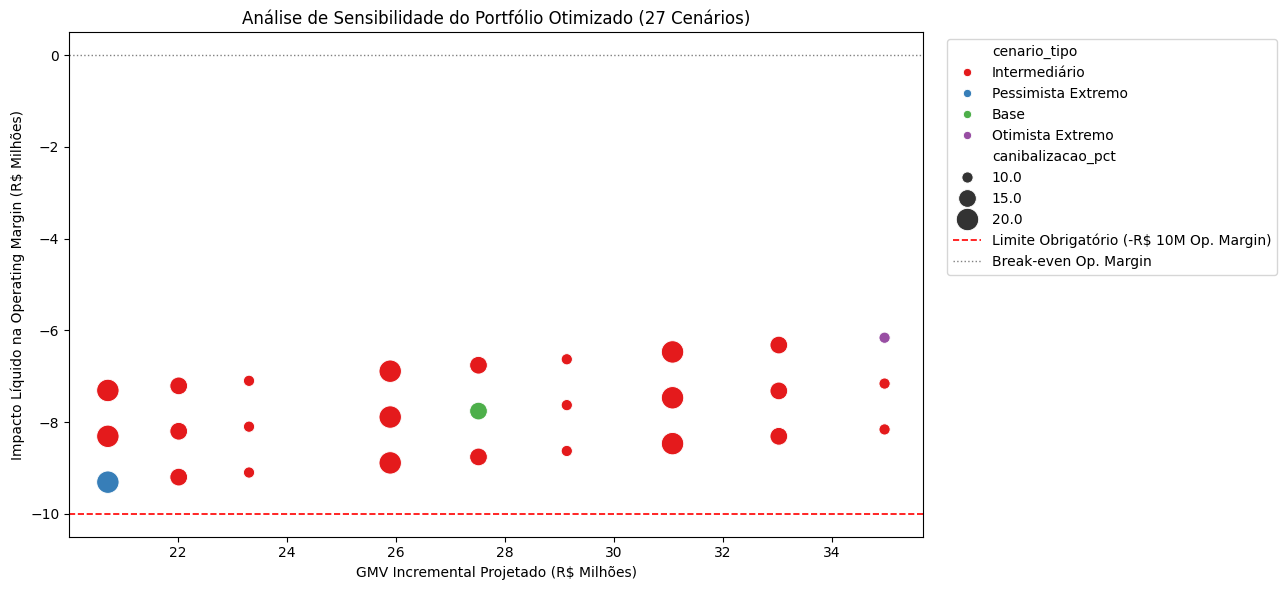

In [4]:
plt.figure(figsize=(13, 6))
sns.scatterplot(
    data=sensitivity_df,
    x="gmv_incremental_m",
    y="operating_margin_incremental_m",
    hue="cenario_tipo",
    size="canibalizacao_pct",
    sizes=(65, 260),
    palette="Set1"
)
plt.axhline(-10.0, color="red", linestyle="--", linewidth=1.2, label="Limite Obrigatório (-R$ 10M Op. Margin)")
plt.axhline(0.0, color="gray", linestyle=":", linewidth=1.0, label="Break-even Op. Margin")
plt.title("Análise de Sensibilidade do Portfólio Otimizado (27 Cenários)")
plt.xlabel("GMV Incremental Projetado (R$ Milhões)")
plt.ylabel("Impacto Líquido na Operating Margin (R$ Milhões)")
plt.legend(bbox_to_anchor=(1.02, 1), loc="upper left")
plt.tight_layout()
plt.savefig(os.path.join(FIGURES_DIR, "05_sensibilidade.png"), bbox_inches="tight", dpi=150)
plt.show()


## 3. Exportação dos Cenários


In [5]:
sens_path = os.path.join(REPORTS_DIR, "sensibilidade_cenarios.csv")
sensitivity_df.to_csv(sens_path, index=False)
print("Análise de sensibilidade salva em:", sens_path)


Análise de sensibilidade salva em: ./outputs/reports/sensibilidade_cenarios.csv
